<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/Customer_Segmentation_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Customer Segmentation Guide

Customer segmentation is the process of dividing a customer base into groups of individuals that are similar in specific ways relevant to marketing, such as age, gender, interests, and spending habits.

In this notebook, we will perform **RFM Analysis** and use **K-Means Clustering** to segment customers based on their transaction history:
*   **Recency (R):** How recently did the customer make a purchase?
*   **Frequency (F):** How often do they make a purchase?
*   **Monetary Value (M):** How much money do they spend?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Generate mock transaction data for demonstration
np.random.seed(42)
n_transactions = 1000
customer_ids = [f"CUST_{i:04d}" for i in np.random.randint(1, 150, n_transactions)]
transaction_dates = pd.date_range(start="2023-01-01", end="2023-12-31", periods=n_transactions)
amounts = np.random.exponential(scale=50, size=n_transactions) + 5

df = pd.DataFrame({
    'CustomerID': customer_ids,
    'TransactionDate': transaction_dates,
    'Amount': amounts
})
display(df.head())

,CustomerID,TransactionDate,Amount
0,CUST_0103,2023-01-01 00:00:00.000000000,22.410166
1,CUST_0093,2023-01-01 08:44:41.081081081,67.598524
2,CUST_0015,2023-01-01 17:29:22.162162162,42.501512
3,CUST_0107,2023-01-02 02:14:03.243243243,43.227422
4,CUST_0072,2023-01-02 10:58:44.324324324,37.801043


### Step 1: Calculate RFM Metrics

We define a reference date (usually the day after the last transaction in the dataset) and calculate Recency, Frequency, and Monetary values for each customer.

In [2]:
reference_date = df['TransactionDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'TransactionDate': lambda x: (reference_date - x.max()).days, # Recency
    'CustomerID': 'count',                                       # Frequency
    'Amount': 'sum'                                             # Monetary Value
})

rfm.rename(columns={
    'TransactionDate': 'Recency',
    'CustomerID': 'Frequency',
    'Amount': 'Monetary'
}, inplace=True)

display(rfm.head())

,Recency,Frequency,Monetary
CustomerID,,,
CUST_0001,4,13,798.470966
CUST_0002,217,5,258.134958
CUST_0003,70,7,529.925506
CUST_0004,81,6,634.495955
CUST_0005,37,10,312.464979


### Step 2: Feature Scaling

K-Means is sensitive to the scale of the features, so we must standardize the RFM values to have a mean of 0 and a standard deviation of 1.

In [3]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)
rfm_scaled_df = pd.DataFrame(rfm_scaled, index=rfm.index, columns=rfm.columns)
display(rfm_scaled_df.head())

,Recency,Frequency,Monetary
CustomerID,,,
CUST_0001,-0.966932,2.311742,2.193158
CUST_0002,2.974946,-0.629129,-0.567995
CUST_0003,0.254495,0.106088,0.820873
CUST_0004,0.458066,-0.261520,1.355235
CUST_0005,-0.356219,1.208915,-0.290365


### Step 3: Apply K-Means Clustering

We fit the K-Means algorithm to group the customers (e.g., into 4 distinct segments).

In [4]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Calculate mean values for each cluster to analyze profiles
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'Count'})

display(cluster_summary)

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,39.965517,10.413793,652.118343,29
1,39.090909,7.381818,407.874427,55
2,44.617021,4.404255,196.805921,47
3,165.277778,4.722222,246.076423,18


### Finding the Optimal Number of Clusters (Elbow Method)

To determine the best value for $K$ (number of clusters), we calculate the Within-Cluster Sum of Squares (WCSS / Inertia) for multiple $K$ values and plot them. We look for the "elbow" point where the rate of decrease in inertia sharply slows down.

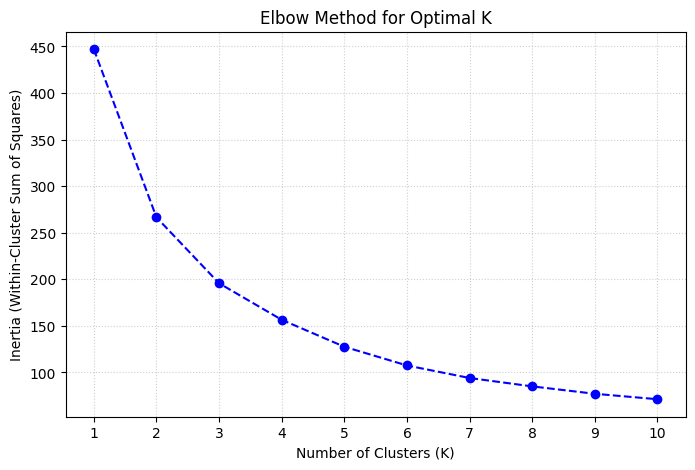

In [6]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method for Optimal K')
plt.xticks(K_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Step 5: 3D Visualization of Customer Segments

To better understand how the clusters are separated in space, we can plot Recency, Frequency, and Monetary Value on a 3D scatter plot, coloring each data point by its assigned cluster.

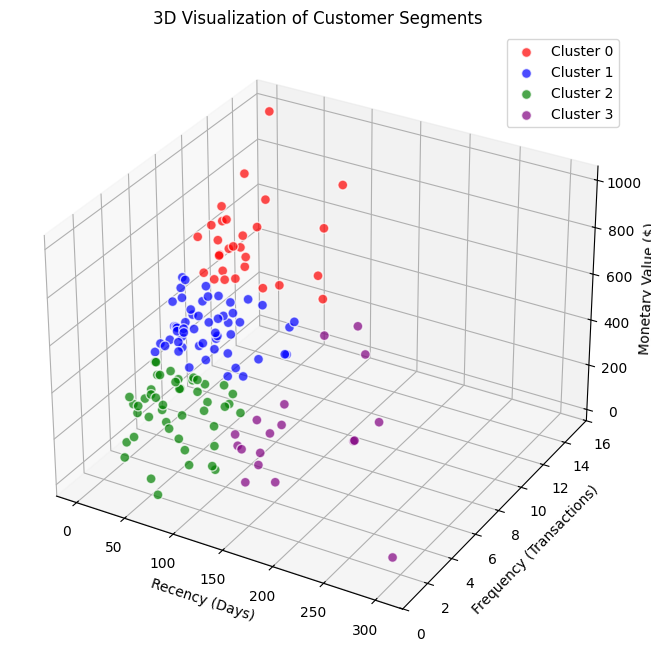

In [7]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Define colors for our 4 clusters
colors = ['red', 'blue', 'green', 'purple']

for cluster in range(4):
    clustered_data = rfm[rfm['Cluster'] == cluster]
    ax.scatter(
        clustered_data['Recency'],
        clustered_data['Frequency'],
        clustered_data['Monetary'],
        c=colors[cluster],
        label=f'Cluster {cluster}',
        s=50,
        alpha=0.7,
        edgecolors='w'
    )

ax.set_xlabel('Recency (Days)')
ax.set_ylabel('Frequency (Transactions)')
ax.set_zlabel('Monetary Value ($)')
ax.set_title('3D Visualization of Customer Segments')
ax.legend()
plt.show()

### Silhouette Score Analysis

The Silhouette Score measures how similar an object is to its own cluster compared to other clusters. A higher silhouette score indicates that the object is well matched to its own cluster and poorly matched to neighboring clusters.

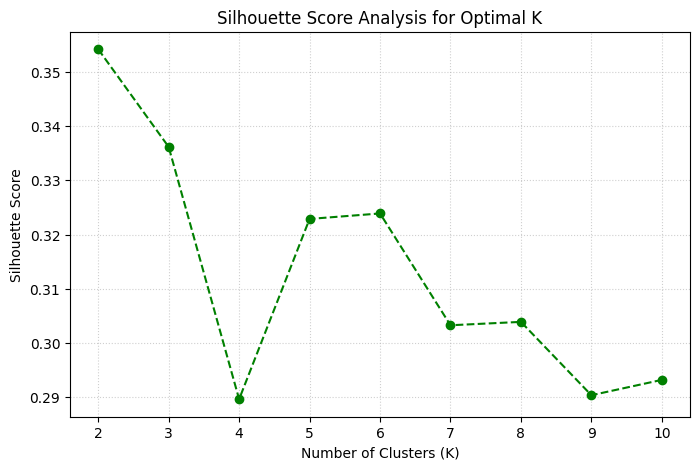

In [8]:
from sklearn.metrics import silhouette_score

sil_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    sil_scores.append(score)

# Plotting the Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(K_range_sil, sil_scores, marker='o', linestyle='--', color='g')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Analysis for Optimal K')
plt.xticks(K_range_sil)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [9]:
# Exporting the cluster summary to a CSV file
export_filename = 'customer_segment_summary.csv'
cluster_summary.to_csv(export_filename)
print(f"Successfully exported cluster summary to: {export_filename}")

Successfully exported cluster summary to: customer_segment_summary.csv


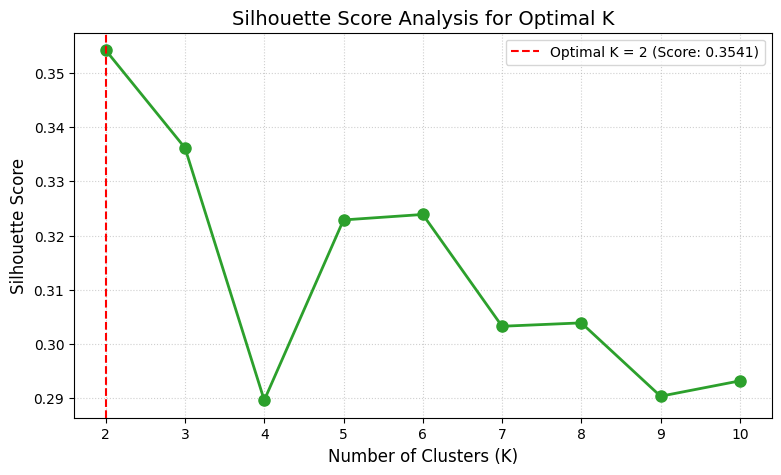

Silhouette Score analysis suggests the optimal number of clusters is K = 2 with a score of 0.3541.


In [10]:
from sklearn.metrics import silhouette_score
import numpy as np

sil_scores = []
k_values = list(range(2, 11))

# Calculate silhouette scores for K ranging from 2 to 10
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    sil_scores.append(score)

# Determine the K with the highest silhouette score
optimal_k_sil = k_values[np.argmax(sil_scores)]
max_score = max(sil_scores)

# Plotting
plt.figure(figsize=(9, 5))
plt.plot(k_values, sil_scores, marker='o', linestyle='-', color='#2ca02c', linewidth=2, markersize=8)
plt.axvline(x=optimal_k_sil, color='red', linestyle='--', label=f'Optimal K = {optimal_k_sil} (Score: {max_score:.4f})')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score Analysis for Optimal K', fontsize=14)
plt.xticks(k_values)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best')
plt.show()

print(f"Silhouette Score analysis suggests the optimal number of clusters is K = {optimal_k_sil} with a score of {max_score:.4f}.")

In [11]:
# Apply K-Means with K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['Cluster_K3'] = kmeans_3.fit_predict(rfm_scaled)

# Calculate mean metrics for the K=3 configuration
cluster_summary_k3 = rfm.groupby('Cluster_K3').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster_K3': 'count'
}).rename(columns={'Cluster_K3': 'Count'})

print("=== Cluster Summary (K=3) ===")
display(cluster_summary_k3)

=== Cluster Summary (K=3) ===


,Recency,Frequency,Monetary,Count
Cluster_K3,,,,
0,38.041096,5.410959,269.229548,73
1,149.541667,4.750000,238.815497,24
2,38.750000,9.442308,569.970199,52


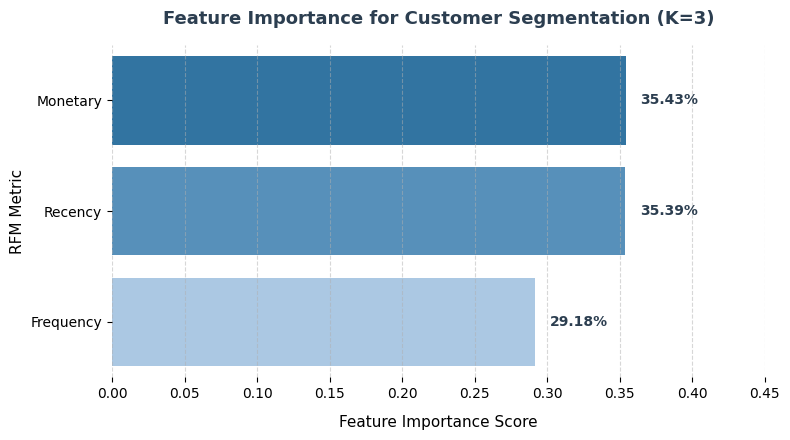

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Prepare features and target labels
X = rfm_scaled_df
y = rfm['Cluster_K3']

# Fit a Random Forest to extract feature importances
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X, y)

# Create a DataFrame for visual mapping
importances = rf_model.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plotting Feature Importances with a professional, clean palette
plt.figure(figsize=(8, 4.5))
professional_palette = ['#1f77b4', '#4793ca', '#a2c8ec']
sns.barplot(x='Importance', y='Feature', data=importance_df, palette=professional_palette, hue='Feature', legend=False)

plt.title('Feature Importance for Customer Segmentation (K=3)', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
plt.xlabel('Feature Importance Score', fontsize=11, labelpad=10)
plt.ylabel('RFM Metric', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Annotate bars with percentages
for index, value in enumerate(importance_df['Importance']):
    plt.text(value + 0.01, index, f"{value:.2%}", va='center', fontweight='semibold', color='#2c3e50')

plt.xlim(0, 0.45)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

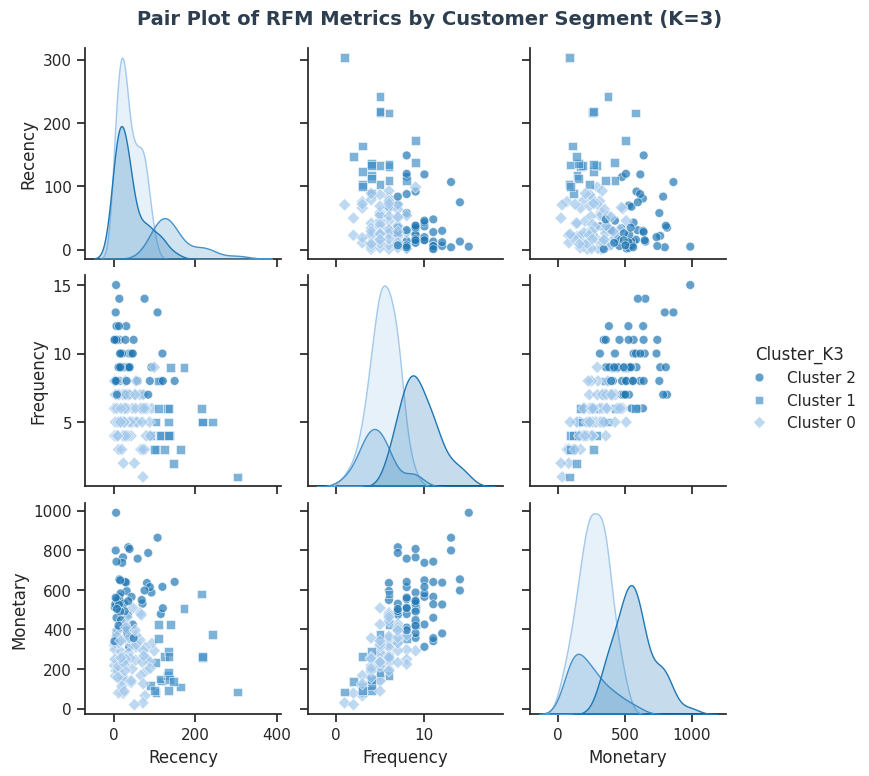

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a copy of the RFM dataframe for plotting
rfm_plot = rfm[['Recency', 'Frequency', 'Monetary', 'Cluster_K3']].copy()
rfm_plot['Cluster_K3'] = rfm_plot['Cluster_K3'].map({0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2'})

# Set the aesthetic style
sns.set_theme(style="ticks")

# Plotting pair plot with professional muted colors
professional_palette = ['#1f77b4', '#4793ca', '#a2c8ec']

g = sns.pairplot(
    rfm_plot,
    hue='Cluster_K3',
    palette=professional_palette,
    diag_kind='kde',
    markers=["o", "s", "D"],
    plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'w'},
    height=2.5
)

g.fig.suptitle('Pair Plot of RFM Metrics by Customer Segment (K=3)', y=1.03, fontsize=14, fontweight='bold', color='#2c3e50')
plt.show()

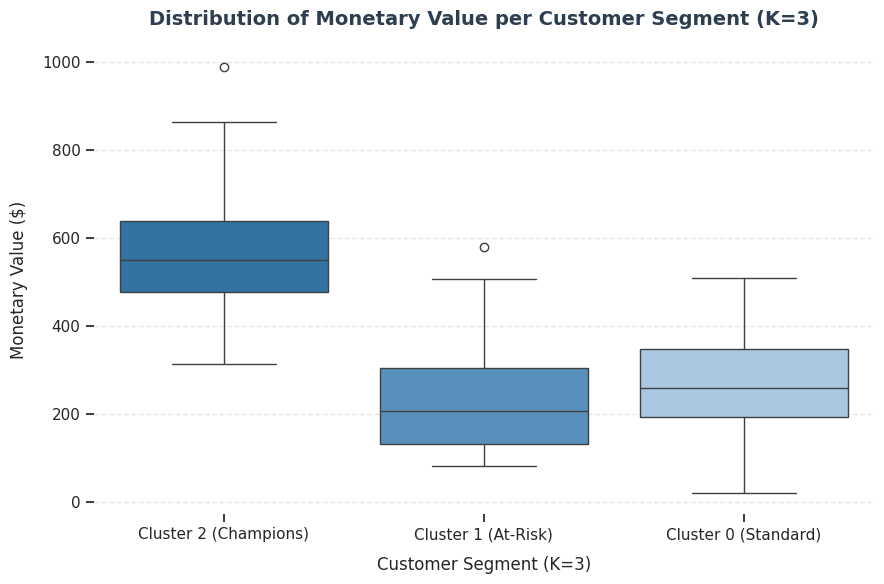

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a copy of the RFM dataframe for plotting
rfm_box = rfm.copy()
rfm_box['Cluster_K3'] = rfm_box['Cluster_K3'].map({0: 'Cluster 0 (Standard)', 1: 'Cluster 1 (At-Risk)', 2: 'Cluster 2 (Champions)'})

# Plotting Monetary Value Distribution per Cluster
plt.figure(figsize=(9, 6))
professional_palette = ['#1f77b4', '#4793ca', '#a2c8ec']

sns.boxplot(
    x='Cluster_K3',
    y='Monetary',
    data=rfm_box,
    palette=professional_palette,
    hue='Cluster_K3',
    legend=False
)

plt.title('Distribution of Monetary Value per Customer Segment (K=3)', fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
plt.xlabel('Customer Segment (K=3)', fontsize=12, labelpad=10)
plt.ylabel('Monetary Value ($)', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

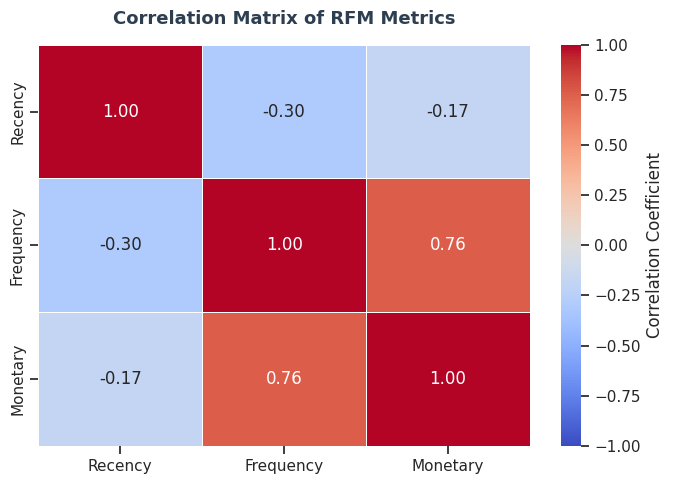

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the correlation matrix for the raw RFM metrics
corr_matrix = rfm[['Recency', 'Frequency', 'Monetary']].corr()

# Plotting the correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title('Correlation Matrix of RFM Metrics', fontsize=13, fontweight='bold', pad=15, color='#2c3e50')
plt.tight_layout()
plt.show()

### Executive Summary of Customer Segments ($K=3$)

Based on our $K=3$ clustering model, the customer base has been categorized into three distinct strategic profiles. Below is the detailed breakdown derived from the average metrics of each segment:

| Segment Profile | Average Recency (Days since last purchase) | Average Frequency (Total transactions) | Average Monetary (Total spend $) | Customer Count | Percentage of Base |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Cluster 2: Champions (High-Value)** | ~38.75 days | 9.44 | $569.97 | 52 | ~34.9% |
| **Cluster 0: Standard (Active & Steady)** | ~38.04 days | 5.41 | $269.23 | 73 | ~49.0% |
| **Cluster 1: At-Risk (Churned/Inactive)** | ~149.54 days | 4.75 | $238.82 | 24 | ~16.1% |

---

### Strategic Action Plans

#### 1. Cluster 2: Champions (High-Value)
*   **Characteristics:** These are highly engaged, loyal, and premium spending customers. They buy frequently, spent the most, and have purchased very recently.
*   **Strategic Action:**
    *   Enroll them in VIP/loyalty reward programs.
    *   Provide early access to new product launches.
    *   Request reviews or testimonials to leverage their brand advocacy.

#### 2. Cluster 0: Standard (Active & Steady)
*   **Characteristics:** This is your largest segment. They are active and buy recently but purchase at a moderate frequency and average ticket size.
*   **Strategic Action:**
    *   Implement cross-selling and up-selling strategies to increase their average basket value.
    *   Send targeted product recommendation newsletters based on past purchase history.

#### 3. Cluster 1: At-Risk (Churned/Inactive)
*   **Characteristics:** These customers have moderate baseline value and frequency, but they have not interacted with your brand in almost 5 months (~150 days).
*   **Strategic Action:**
    *   Launch automated win-back email campaigns with special incentives (e.g., "We miss you! Here is 20% off your next order").
    *   Conduct feedback surveys to understand why they stopped purchasing.

### Detailed Characterization Report ($K=3$)

Using the metrics aggregated in the `cluster_summary_k3` DataFrame, we can classify our three customer segments according to their purchasing behavior:

#### 📊 Segment Comparison Metrics

| Cluster ID | Segment Name | Avg Recency (Days) | Avg Frequency (Purchases) | Avg Monetary ($) | Customer Count |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **0** | **Steady Contributors** | ~38.04 | ~5.41 | $269.23 | 73 (49.0%) |
| **1** | **At-Risk / Lapsed** | ~149.54 | ~4.75 | $238.82 | 24 (16.1%) |
| **2** | **High-Value Champions** | ~38.75 | ~9.44 | $569.97 | 52 (34.9%) |

---

### 🔍 Deep-Dive Profiles

1. **Cluster 2: High-Value Champions**
   * **Metrics:** Recency is low (~39 days), Frequency is highest (~9.44 transactions), and Monetary spend is the absolute highest (~$569.97).
   * **Interpretation:** These are your most valuable loyalists. They buy frequently, spend heavily, and have bought from you very recently.

2. **Cluster 0: Steady Contributors**
   * **Metrics:** Recency is low (~38 days), Frequency is moderate (~5.41 transactions), and Monetary value is moderate (~$269.23).
   * **Interpretation:** This represents the majority of your active customer base. They purchase regularly and maintain steady relationships, but have potential for value up-selling.

3. **Cluster 1: At-Risk / Lapsed**
   * **Metrics:** Recency is exceptionally high (~150 days), with low-to-moderate frequency (~4.75) and moderate spend (~$238.82).
   * **Interpretation:** These customers are slipping away. They have not made a purchase in nearly 5 months and require immediate reactivation strategies.

In [17]:
# Export the K=3 cluster summary to a CSV file
export_k3_filename = 'customer_segment_summary_k3.csv'
cluster_summary_k3.to_csv(export_k3_filename)
print(f"Successfully exported K=3 cluster summary to: {export_k3_filename}")

Successfully exported K=3 cluster summary to: customer_segment_summary_k3.csv


### Predicting Churn Probabilities using RFM Metrics

To predict a continuous probability of churn for each customer, we can:
1. Define a binary churn target variable (e.g., `Churned = 1` if a customer has not purchased in over 90 days, else `0`).
2. Train a probabilistic classifier (like `LogisticRegression` or `RandomForestClassifier`) using **Frequency** and **Monetary** value as our predictors (since using Recency directly would cause data leakage with our target definition).
3. Extract the predicted probability of the positive class (`1`).

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Define the target label (e.g., Churned = 1 if Recency > 90 days, else 0)
rfm['Is_Churned'] = (rfm['Recency'] > 90).astype(int)

# 2. Define predictors (We exclude Recency to avoid target leakage)
X_churn = rfm[['Frequency', 'Monetary']]
y_churn = rfm['Is_Churned']

# 3. Scale features specifically for our predictive model
scaler_churn = StandardScaler()
X_churn_scaled = scaler_churn.fit_transform(X_churn)

# 4. Fit a Logistic Regression classifier to get well-calibrated probabilities
model = LogisticRegression(random_state=42)
model.fit(X_churn_scaled, y_churn)

# 5. Predict probabilities
# predict_proba returns [prob_active, prob_churn]
rfm['Churn_Probability'] = model.predict_proba(X_churn_scaled)[:, 1]

# Display top customers sorted by their predicted churn risk
display(rfm[['Recency', 'Frequency', 'Monetary', 'Is_Churned', 'Churn_Probability']].sort_values(by='Churn_Probability', ascending=False).head(10))

,Recency,Frequency,Monetary,Is_Churned,Churn_Probability
CustomerID,,,,,
CUST_0077,71,1,29.800362,0,0.380296
CUST_0087,304,1,84.320710,1,0.378179
CUST_0125,50,2,20.716517,0,0.346459
CUST_0031,23,2,78.623738,0,0.344300
CUST_0102,147,2,137.206102,1,0.342122
CUST_0020,76,3,65.799234,0,0.312186
CUST_0091,11,3,79.720196,0,0.311693
CUST_0007,103,3,81.583018,1,0.311627
CUST_0119,100,3,93.516482,1,0.311205


In [19]:
# Filter for customers with Churn_Probability above 0.3
high_risk_customers = rfm[rfm['Churn_Probability'] > 0.3][['Recency', 'Frequency', 'Monetary', 'Is_Churned', 'Churn_Probability']].sort_values(by='Churn_Probability', ascending=False)

print(f"Found {len(high_risk_customers)} high-risk customers with Churn Probability > 0.3:")
display(high_risk_customers)

Found 14 high-risk customers with Churn Probability > 0.3:


,Recency,Frequency,Monetary,Is_Churned,Churn_Probability
CustomerID,,,,,
CUST_0077,71,1,29.800362,0,0.380296
CUST_0087,304,1,84.320710,1,0.378179
CUST_0125,50,2,20.716517,0,0.346459
CUST_0031,23,2,78.623738,0,0.344300
CUST_0102,147,2,137.206102,1,0.342122
CUST_0020,76,3,65.799234,0,0.312186
CUST_0091,11,3,79.720196,0,0.311693
CUST_0007,103,3,81.583018,1,0.311627
CUST_0119,100,3,93.516482,1,0.311205


### Visualizing Churn Probability Distribution

Let's plot the distribution of churn probabilities to understand the overall risk within our customer base.

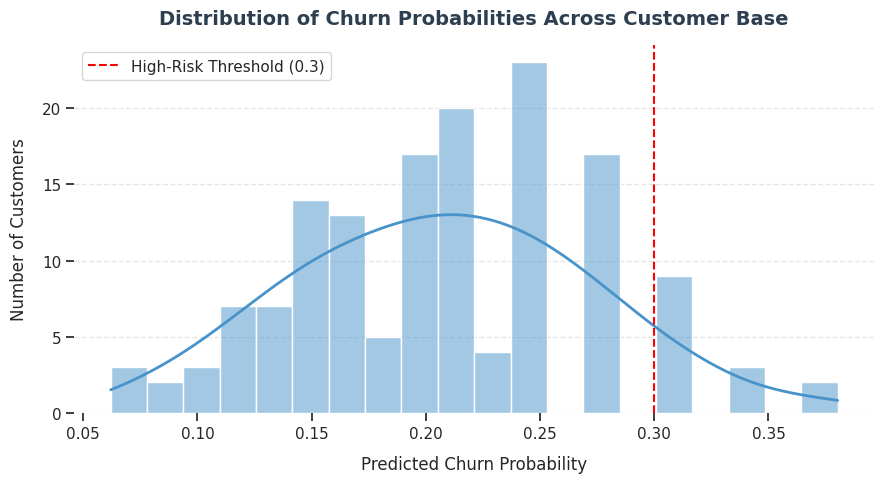

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

# Plotting distribution of Churn Probabilities
sns.histplot(
    data=rfm,
    x='Churn_Probability',
    kde=True,
    color='#4793ca',
    bins=20,
    edgecolor='white',
    line_kws={'linewidth': 2}
)

# Highlight the high-risk threshold of 0.3
plt.axvline(
    x=0.3,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='High-Risk Threshold (0.3)'
)

plt.title('Distribution of Churn Probabilities Across Customer Base', fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
plt.xlabel('Predicted Churn Probability', fontsize=12, labelpad=10)
plt.ylabel('Number of Customers', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='best')

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()